# Resultados integrados y presentación
Las tres ramas de compañeros se conservan mediante merges en una rama nueva. Este notebook resume resultados reproducibles y la app local; no ejecuta optimización ni altera los archivos originales de los autores.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'config/project2/base.yaml').exists())
sys.path.insert(0, str(ROOT / 'src'))
from bee_sim.analysis.project2_comparison import build_comparison
data = build_comparison(ROOT)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})


In [2]:
metrics = ['total_resource_obtained','mean_distance_m','competition_pressure','hive_balance_jain']
display(data['summary'].query('metric in @metrics')[['method','metric','mean','ci95_low','ci95_high']])

,method,metric,mean,ci95_low,ci95_high
0,RANDOM,total_resource_obtained,721.661992,717.691165,725.765647
3,RANDOM,mean_distance_m,1618.409000,1617.146014,1619.604807
6,RANDOM,competition_pressure,0.000322,0.000293,0.000354
7,RANDOM,hive_balance_jain,0.954928,0.954106,0.955791
9,GREEDY,total_resource_obtained,914.375650,906.817175,922.113160
12,GREEDY,mean_distance_m,1318.738395,1314.009308,1323.534377
15,GREEDY,competition_pressure,0.000253,0.000146,0.000386
16,GREEDY,hive_balance_jain,0.988499,0.987055,0.989923
18,NSGA2,total_resource_obtained,927.786708,919.911956,935.651559
21,NSGA2,mean_distance_m,1274.466613,1270.681268,1278.004653


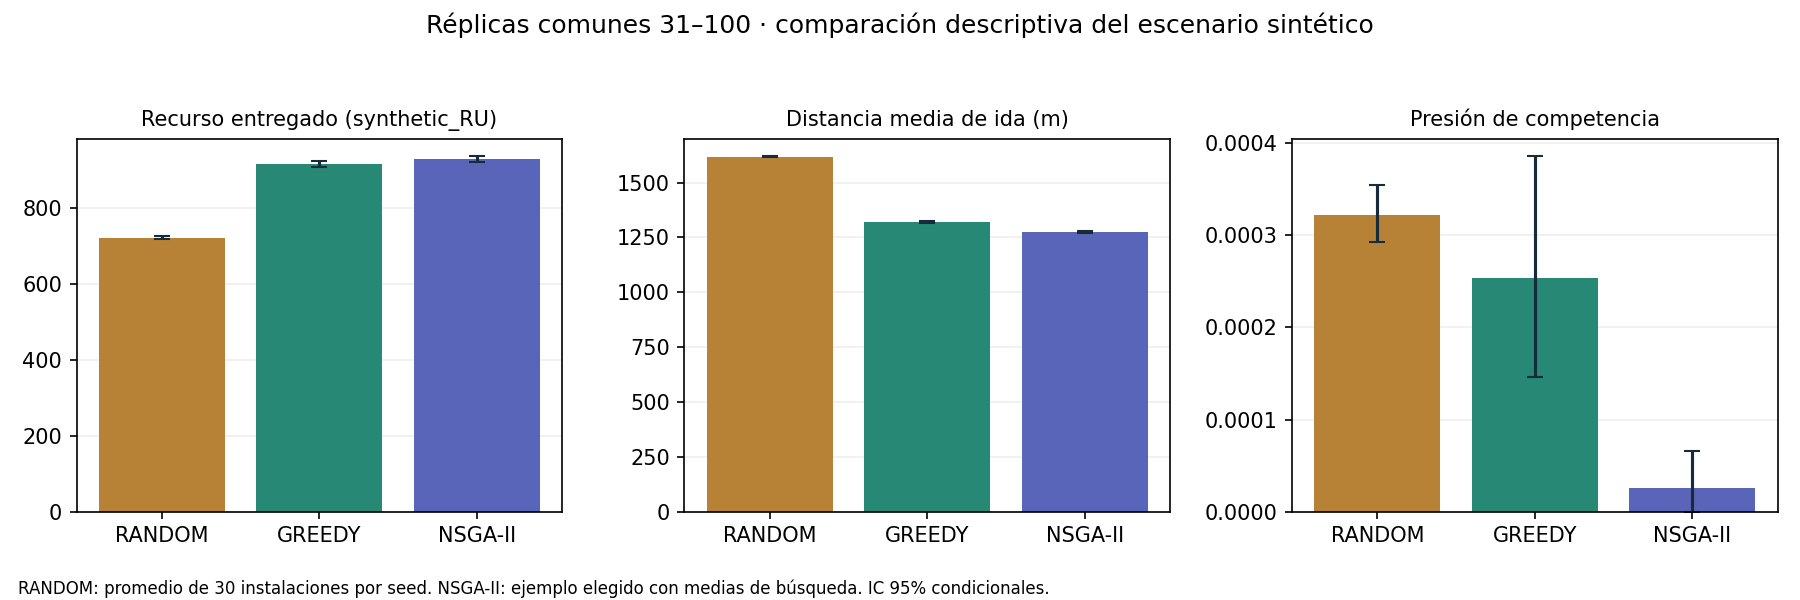

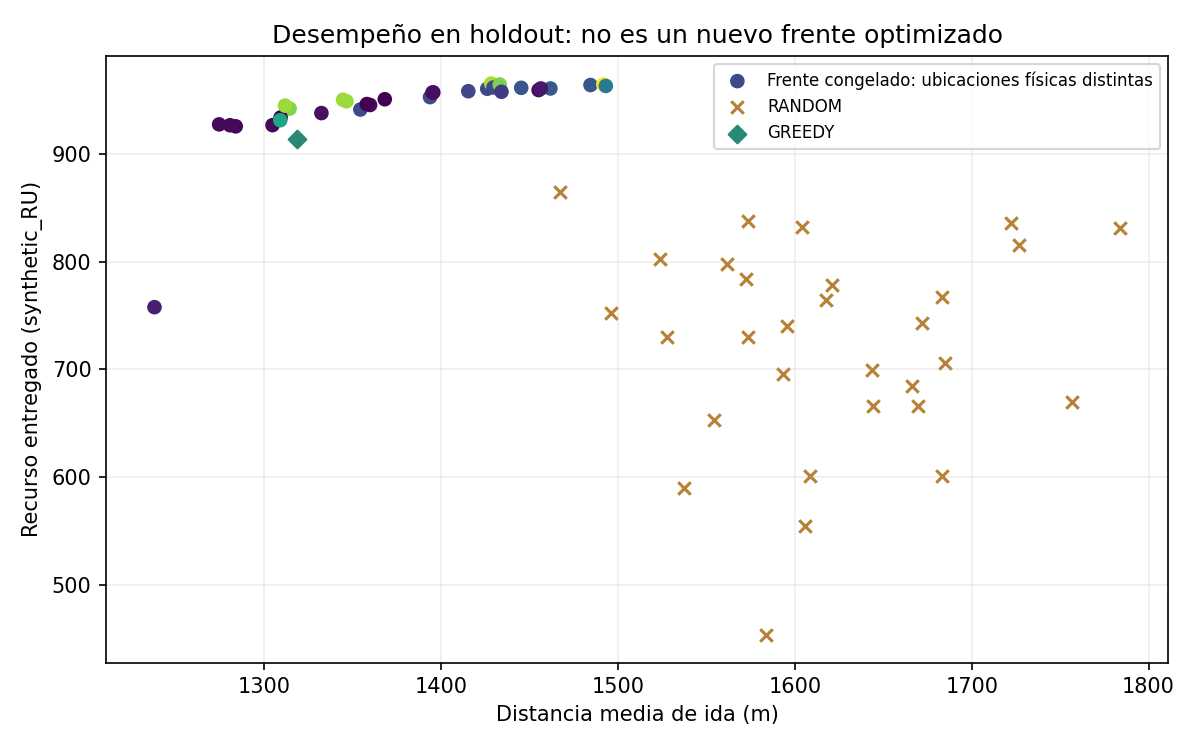

In [3]:
from IPython.display import Image
for name in ['comparison_methods.png','comparison_tradeoffs.png']:
    path = ROOT / 'results/project2/integration' / name
    if path.exists():
        display(Image(filename=str(path)))

## Qué ya está listo
- Geografía real, restricciones de zonas libres de abejas y distancias métricas.
- Motor diario común, recursos no negativos, semillas compartidas y métricas uniformes.
- RANDOM, GREEDY y NSGA-II integrados con trazabilidad de resultados históricos.
- Comparaciones pareadas y mapas interactivos de colmenas, parches, recursos y viajes.

## App para presentar
Desde la raíz del repositorio, instalar `requirements.txt` en un entorno virtual y ejecutar:
```powershell
python -m streamlit run app/app.py
```
La pestaña de comparación usa resultados archivados. En el mapa, pulsar **Simular escenario** y mover día/minuto para inspeccionar viajes del log. Los íconos representan viajes activos, no abejas identificadas individualmente. Los sliders cambian supuestos de recurso, regeneración, radio, viajes, competencia, distancia y velocidad. Una solución NSGA-II guardada se reevalúa con otros supuestos; eso no constituye reoptimizarla.

## Qué falta antes de concluir ecológicamente
Calibrar la relación entre área y recurso floral, unidades de néctar/polen, regeneración, agotamiento, demanda, viajes y competencia. Dryad permite comparar patrones de flores/visitas respetando esfuerzo y unidades, no validar RU como si fueran mediciones. Hacen falta escenarios y sensibilidad con presupuesto explícito, múltiples semillas de búsqueda, decisión de colocalización y datos espaciales/temporales compatibles. No hay recomendación validada de ubicaciones reales.

## Regenerar tablas y figuras
```powershell
python scripts/project2_compare.py
python -m unittest discover -s tests/project2 -v
```
Consultar `docs/project2/INTEGRATION_REVIEW.md` para incidencias y `README_INTEGRATION.md` para ejecución.